# Fashion Deep Learning Recommendation Systems

*Download the Dataset from here <a href=https://www.kaggle.com/datasets/paramaggarwal/fashion-product-images-small>Dataset</a>
All the code is given. You need to download the data and train the model using the following code and save the model. Then, create a streamlit app to recommend similar products.

<img src='https://ecommercecoffeebreak.com/wp-content/uploads/2026/04/fashion-ecommerce-size-recommendation-systems-that-cut-retur.webp'>

## Introduction

This project develops an image-based fashion recommendation system using **Deep Learning and Computer Vision**.

The goal is to recommend visually similar fashion products based on an input image. Instead of relying on product descriptions or user ratings, the system uses visual features extracted from product images.

### Project Objectives

- Extract visual features from fashion images using a pretrained **ResNet50** model.
- Represent each product as a **2,048-dimensional feature vector**.
- Use **Nearest Neighbors** and Euclidean distance to identify similar products.
- Display the **top 5 visually similar recommendations** for a selected or uploaded image.
- Deploy an interactive **Streamlit application on Hugging Face Spaces**.

### Technologies Used

Python, TensorFlow/Keras, ResNet50, Scikit-learn, NumPy, Pillow, Matplotlib, Streamlit.

The deployed application uses a collection of **44,441 precomputed image feature vectors** to perform similarity searches.

In [52]:
import numpy as np
import pickle as pkl
import tensorflow as tf
from tensorflow.keras.applications.resnet50 import ResNet50,preprocess_input
from tensorflow.keras.preprocessing import image
from tensorflow.keras.layers import GlobalMaxPool2D
import matplotlib.pyplot as plt
from matplotlib.patches import FancyBboxPatch, FancyArrowPatch
from PIL import Image as PILImage
from pathlib import Path
from IPython.display import Image

from sklearn.neighbors import NearestNeighbors
import os
from numpy.linalg import norm
import warnings
warnings.filterwarnings("ignore")

In [2]:
#Extract Filenames from Folder

In [3]:
filenames = []
for file in os.listdir('images'):
    filenames.append(os.path.join('images',file))
    

In [4]:
len(filenames)

44441

In [5]:
#Importing ResNet50 Model and Cofiguration

In [6]:
model = ResNet50(weights='imagenet', include_top=False, input_shape=(160,160,3))
model.trainable = False

model = tf.keras.models.Sequential([model,
                                   GlobalMaxPool2D()
                                   ])
model.summary()

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                         ┃ Output Shape                ┃         Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━┩
│ resnet50 (Functional)                │ (None, 5, 5, 2048)          │      23,587,712 │
├──────────────────────────────────────┼─────────────────────────────┼─────────────────┤
│ global_max_pooling2d                 │ (None, 2048)                │               0 │
│ (GlobalMaxPooling2D)                 │                             │                 │
└──────────────────────────────────────┴─────────────────────────────┴─────────────────┘

 Total params: 23,587,712 (89.98 MB)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 23,587,712 (89.98 MB)

In [7]:
#Extracting Fetaures from Image

In [8]:
def extract_features_from_images(image_path, model):
    img = image.load_img(image_path, target_size=(160,160))
    img_array = image.img_to_array(img)
    img_expand_dim = np.expand_dims(img_array, axis=0)
    img_preprocess = preprocess_input(img_expand_dim)
    result = model.predict(img_preprocess, verbose=0).flatten()
    norm_result = result/norm(result)
    return norm_result

In [9]:
extract_features_from_images(filenames[0], model)

array([0.00243007, 0.02699806, 0.00685794, ..., 0.00206077, 0.02256775,
       0.07967658], dtype=float32)

In [10]:
image_features = []
for file in filenames:
    image_features.append(extract_features_from_images(file, model))
image_features

[array([0.00243007, 0.02699806, 0.00685794, ..., 0.00206077, 0.02256775,
        0.07967658], dtype=float32),
 array([0.        , 0.0297017 , 0.00538263, ..., 0.        , 0.        ,
        0.07157836], dtype=float32),
 array([0.        , 0.03010744, 0.0115208 , ..., 0.        , 0.        ,
        0.05538023], dtype=float32),
 array([0.        , 0.05261476, 0.01214573, ..., 0.00209349, 0.04146741,
        0.04888803], dtype=float32),
 array([0.        , 0.05630806, 0.        , ..., 0.0040488 , 0.0136589 ,
        0.04169128], dtype=float32),
 array([0.        , 0.09677272, 0.        , ..., 0.00327738, 0.00557144,
        0.03131388], dtype=float32),
 array([0.        , 0.08983972, 0.        , ..., 0.        , 0.03863792,
        0.0848147 ], dtype=float32),
 array([0.        , 0.0687117 , 0.00196587, ..., 0.00046358, 0.00064587,
        0.02835542], dtype=float32),
 array([0.        , 0.09656847, 0.0049582 , ..., 0.        , 0.04481351,
        0.05781863], dtype=float32),
 array([0.

In [11]:
#Save pickle
with open("Image_features.pkl", "wb") as f:
    pkl.dump(image_features, f, protocol=4)

with open("filenames.pkl", "wb") as f:
    pkl.dump(filenames, f, protocol=4)

In [12]:
#Loading Pickle Files

In [13]:
with open("Image_features.pkl", "rb") as f:
    image_features = pkl.load(f)

with open("filenames.pkl", "rb") as f:
    filenames = pkl.load(f)

In [15]:
np.array(image_features).shape

(44441, 2048)

In [16]:
#Finidng Simialar Images

In [17]:
neighbors = NearestNeighbors(n_neighbors=6, algorithm='brute', metric='euclidean')

In [19]:
neighbors.fit(image_features)

,n_neighbors,6
,radius,1.0
,algorithm,'brute'
,leaf_size,30
,metric,'euclidean'
,p,2
,metric_params,None
,n_jobs,None


In [20]:
input_image = extract_features_from_images('images/16871.jpg', model)

In [28]:
distance,indices = neighbors.kneighbors([input_image]);

In [29]:
indices[0]

array([ 5828, 23502,  5799,  5814,  6257,  6268])

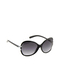

In [30]:
Image('images/16871.jpg')

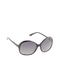

In [31]:
Image(filenames[indices[0][1]])

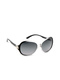

In [32]:
Image(filenames[indices[0][2]])

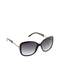

In [33]:
Image(filenames[indices[0][3]])

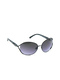

In [34]:
Image(filenames[indices[0][4]])

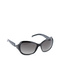

In [35]:
Image(filenames[indices[0][5]])

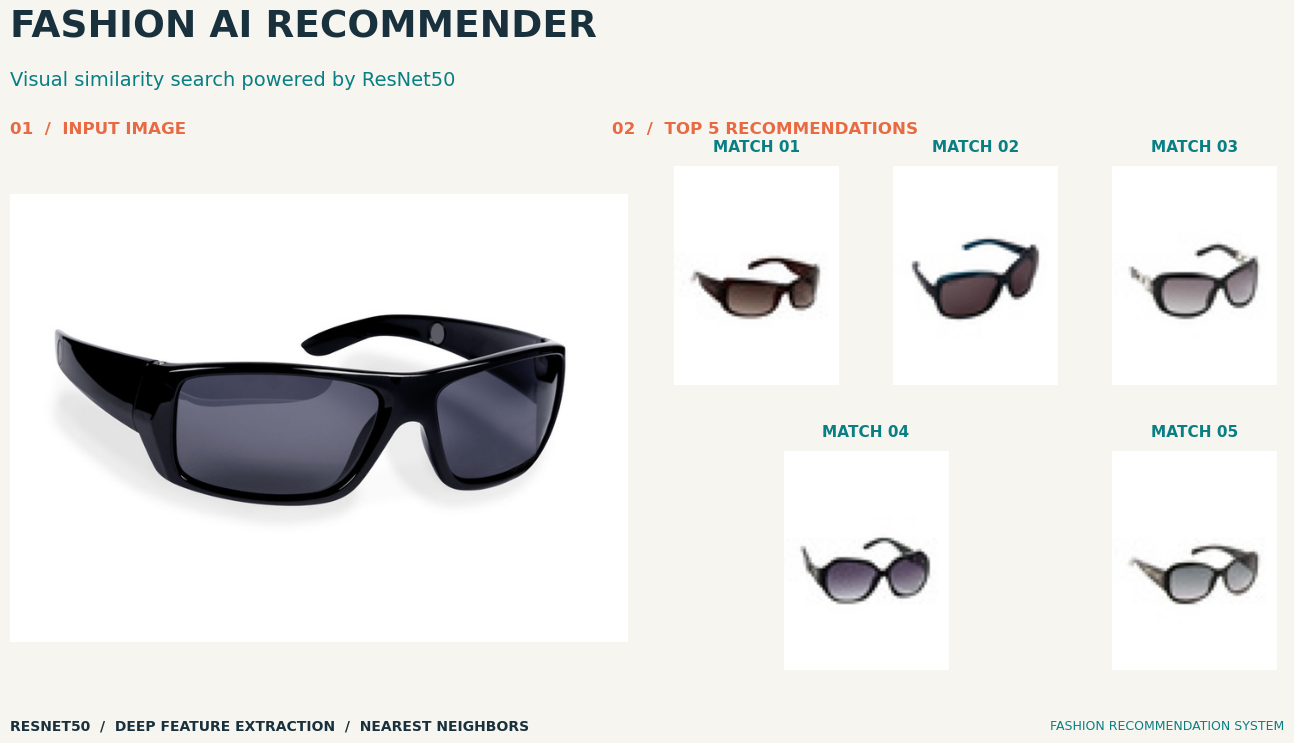

In [56]:
input_path = 'images\sunglasses.jpg'

input_features = np.asarray(
    extract_features_from_images(input_path, model)
).reshape(1, -1)

features = np.asarray(image_features)

neighbors = NearestNeighbors(
    n_neighbors=min(6, len(features)),
    algorithm='brute',
    metric='euclidean'
)
neighbors.fit(features)

distances, indices = neighbors.kneighbors(input_features)

results = [
    (filenames[i], float(d))
    for i, d in zip(indices[0], distances[0])
    if Path(filenames[i]).resolve() != Path(input_path).resolve()
][:5]

assert len(results) == 5, 'Five recommendations are required.'

BG = '#F7F5F0'
INK = '#19313D'
TEAL = '#087F83'
ORANGE = '#E86A43'

fig = plt.figure(figsize=(14, 8), facecolor=BG)

fig.text(
    0.05, 0.92,
    'FASHION AI RECOMMENDER',
    fontsize=27, fontweight='bold', color=INK
)

fig.text(
    0.05, 0.86,
    'Visual similarity search powered by ResNet50',
    fontsize=14, color=TEAL
)

fig.text(
    0.05, 0.80,
    '01  /  INPUT IMAGE',
    fontsize=12, fontweight='bold', color=ORANGE
)

fig.text(
    0.48, 0.80,
    '02  /  TOP 5 RECOMMENDATIONS',
    fontsize=12, fontweight='bold', color=ORANGE
)

gs = fig.add_gridspec(
    2, 6,
    left=0.05, right=0.96,
    top=0.76, bottom=0.13,
    wspace=0.22, hspace=0.30
)

ax = fig.add_subplot(gs[:, :3])
ax.imshow(PILImage.open(input_path).convert('RGB'))
ax.axis('off')

positions = [
    gs[0, 3],
    gs[0, 4],
    gs[0, 5],
    gs[1, 3:5],
    gs[1, 5]
]

for rank, ((path, distance), pos) in enumerate(
    zip(results, positions), start=1
):
    ax = fig.add_subplot(pos)
    ax.imshow(PILImage.open(path).convert('RGB'))
    ax.set_title(
        f'MATCH {rank:02d}',
        fontsize=11,
        fontweight='bold',
        color=TEAL,
        pad=10
    )
    ax.axis('off')

fig.text(
    0.05, 0.055,
    'RESNET50  /  DEEP FEATURE EXTRACTION  /  NEAREST NEIGHBORS',
    fontsize=10, fontweight='bold', color=INK
)

fig.text(
    0.96, 0.055,
    'FASHION RECOMMENDATION SYSTEM',
    fontsize=9, color=TEAL, ha='right'
)

plt.savefig(
    'fashion_ai_recommendations_final.png',
    dpi=300,
    bbox_inches='tight',
    facecolor=BG
)

plt.show()

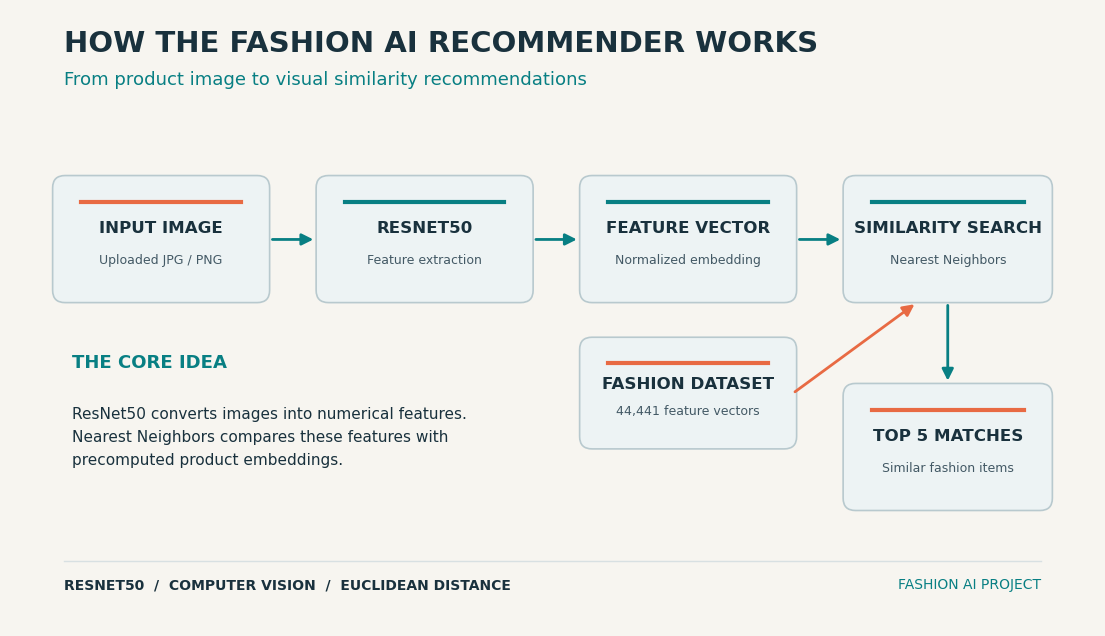

In [60]:
BG = '#F7F5F0'
INK = '#19313D'
TEAL = '#087F83'
ORANGE = '#E86A43'
MUTED = '#435965'
WHITE = '#FFFFFF'

fig, ax = plt.subplots(figsize=(14, 8))
fig.patch.set_facecolor(BG)
ax.set_facecolor(BG)
ax.set_xlim(0, 14)
ax.set_ylim(0, 8)
ax.axis('off')

ax.text(0.7, 7.45, 'HOW THE FASHION AI RECOMMENDER WORKS',
        fontsize=21, weight='bold', color=INK)

ax.text(0.7, 7.02,
        'From product image to visual similarity recommendations',
        fontsize=13, color=TEAL)

def draw_card(x, y, w, h, title, subtitle, accent=TEAL):
    card = FancyBboxPatch(
        (x, y), w, h,
        boxstyle='round,pad=0.15,rounding_size=0.16',
        linewidth=1.2,
        edgecolor='#B8C9CE',
        facecolor='#EDF3F4'
    )
    ax.add_patch(card)

    ax.plot([x + 0.22, x + w - 0.22],
            [y + h - 0.19] * 2,
            color=accent, linewidth=3)

    ax.text(x + w/2, y + h*0.60, title,
            ha='center', va='center',
            fontsize=12, weight='bold', color=INK)

    ax.text(x + w/2, y + h*0.29, subtitle,
            ha='center', va='center',
            fontsize=9, color=MUTED)

def arrow(x1, y1, x2, y2, color=TEAL):
    ax.add_patch(FancyArrowPatch(
        (x1, y1), (x2, y2),
        arrowstyle='-|>',
        mutation_scale=17,
        linewidth=2,
        color=color
    ))

draw_card(0.7, 4.35, 2.5, 1.35,
          'INPUT IMAGE', 'Uploaded JPG / PNG', ORANGE)

draw_card(4.1, 4.35, 2.5, 1.35,
          'RESNET50', 'Feature extraction')

draw_card(7.5, 4.35, 2.5, 1.35,
          'FEATURE VECTOR', 'Normalized embedding')

draw_card(10.9, 4.35, 2.4, 1.35,
          'SIMILARITY SEARCH', 'Nearest Neighbors')

arrow(3.35, 5.02, 3.95, 5.02)
arrow(6.75, 5.02, 7.35, 5.02)
arrow(10.15, 5.02, 10.75, 5.02)

draw_card(7.5, 2.45, 2.5, 1.15,
          'FASHION DATASET', '44,441 feature vectors', ORANGE)

arrow(10.1, 3.02, 11.7, 4.20, ORANGE)

draw_card(10.9, 1.65, 2.4, 1.35,
          'TOP 5 MATCHES', 'Similar fashion items', ORANGE)

arrow(12.1, 4.20, 12.1, 3.15)

ax.text(
    0.8, 3.35,
    'THE CORE IDEA',
    fontsize=13,
    weight='bold',
    color=TEAL
)

ax.text(
    0.8, 2.85,
    'ResNet50 converts images into numerical features.\n'
    'Nearest Neighbors compares these features with\n'
    'precomputed product embeddings.',
    fontsize=11,
    color=INK,
    linespacing=1.7,
    va='top'
)

ax.plot([0.7, 13.3], [0.85, 0.85],
        color='#D8E0E2', linewidth=1)

ax.text(0.7, 0.48,
        'RESNET50  /  COMPUTER VISION  /  EUCLIDEAN DISTANCE',
        fontsize=10, weight='bold', color=INK)

ax.text(13.3, 0.48, 'FASHION AI PROJECT',
        fontsize=10, color=TEAL, ha='right')

plt.savefig(
    'fashion_ai_architecture.png',
    dpi=300,
    bbox_inches='tight',
    facecolor=BG
)

plt.show()

In [ ]:
model.save('resnet_feature_extractor.keras')

Create a streamlit app using this trained model and when I pick one item, it should recommend similar items using  NearestNeighbors(n_neighbors=6, algorithm='brute', metric='euclidean')

## Conclusion

In this project, I developed an image-based fashion recommendation system using **ResNet50 and Nearest Neighbors**.

The system extracts deep visual features from fashion product images and compares them with precomputed feature vectors to retrieve the five nearest products.

### Key Outcomes

- Implemented a deep learning-based image feature extraction pipeline.
- Represented fashion products using 2,048-dimensional embeddings.
- Built a nearest-neighbor similarity search system.
- Generated visual recommendations for fashion products.
- Deployed an interactive Streamlit application on Hugging Face Spaces.

### Limitations and Future Improvements

The system identifies visually similar products based on extracted image features. However, visual similarity does not always guarantee identical product categories, styles, or user preferences.

Future improvements could include evaluating recommendation quality, comparing alternative image encoders, incorporating product metadata, and improving retrieval performance.

### Live Application

https://huggingface.co/spaces/EnYa32/FashionRecommender

The project demonstrates how pretrained Computer Vision models can be combined with similarity search to build a practical recommendation application.